# Postprocessing

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py
import TM26_unet as unet


mGPU = True
MULTIGPU = True

DELETE_OLD_FILES = False
DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

diffLimDir = "dataInputs/"
testDataDir = "output_prep/"
outputDir = "output_post/"
inputDir = "output_infer/"

datasets_name = ["lightfield", "WFSxy", "WFSxy_DM", "WFSxy_DM_intensity", "WFSxy_intensity"]
dataset_name_readable = ["lightfield", "WFSxy", "WFSxy and DM commands", "WFSxy, SHWFS intensity map and DM commands", "WFSxy and SHWFS intensity map"]

batch_size = 64

dataset_numbers = len(datasets_name)



SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True



In [2]:
# for dataset_number in range(dataset_numbers):
dataset_number = 0

## load data

In [3]:
with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
    inference = temp[list(temp.keys())[0]][()]
    
with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    truth = temp[key[0]][()][:]

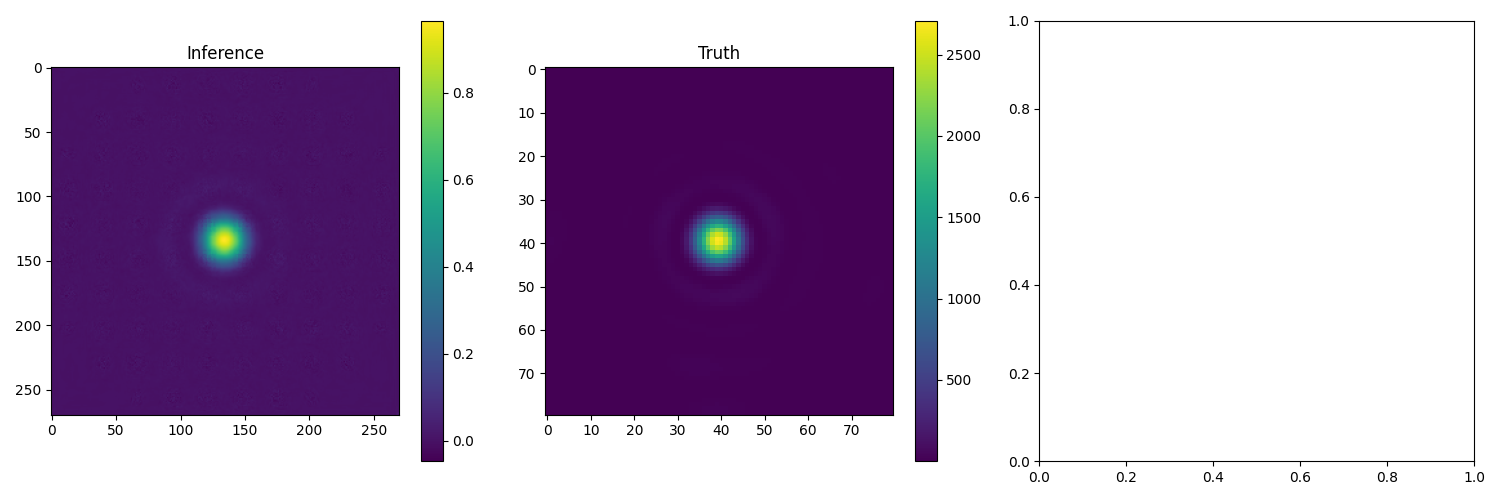

In [17]:
with h5py.File(inputDir+datasets_name[0]+"/predictions.h5", 'r') as temp:
    inference = temp[list(temp.keys())[0]][()]
    
with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    truth = temp[key[0]][()][:]

plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(inference[0])
axes[0].set_title('Inference')
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(truth[0])
axes[1].set_title('Truth')
fig.colorbar(im1, ax=axes[1])

# im2 = axes[2].imshow(inference[0] - truth[0])
# axes[2].set_title('Difference (Inference - Truth)')
# fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## FFT

selon mathft.pro

In [ ]:
import numpy as np


def _mathft_coords(n, dx=1.0, ic=0.0, jc=0.0, inverse=False, ndim=1, single=False):
    '''----------------------------------------------------------------------------
    This is a python translation of mathft, Laurent Jolissaint, Mar 11, 2015
    ----------------------------------------------------------------------------'''
    dtype = np.float32 if single else np.float64
    n = n - (n % 2)
    dx = dtype(dx)
    ic = dtype(ic)
    jc = dtype(jc)

    fnyqu = dtype(0.5) / dx
    df = dtype(1.0) / (n * dx)

    if not inverse:
        coo = np.linspace(-fnyqu, fnyqu - df, n, dtype=dtype)
        if ndim == 1:
            return coo
        return np.meshgrid(coo, coo, indexing="ij")

    coo = np.linspace(-ic * dx, (n - 1 - ic) * dx, n, dtype=dtype)
    if ndim == 1:
        return coo

    coo_y = np.linspace(-jc * dx, (n - 1 - jc) * dx, n, dtype=dtype)
    return np.meshgrid(coo, coo_y, indexing="ij")


def mathft(object, dx=1.0, ic=0.0, jc=0.0, inverse=False, coo=False, single=False):
    '''----------------------------------------------------------------------------
    This is a python translation of mathft, Laurent Jolissaint, Mar 11, 2015
    in:
        object (ndarray): 1 or 2D numpy array of the object to transform
        dx (double): pixel scale
        ic (double): pixel position associated with the (0,0) coordinate in the linear space (the conjugate of the frequency space). JC is not needed if OBJECT is 1D.
    out:
        transformed object (ndarray)
    ----------------------------------------------------------------------------'''
    a = np.asarray(object)

    if a.ndim == 0 or a.ndim > 2:
        raise ValueError("OBJECT MUST BE 1D OR 2D")
    if a.size == 0:
        raise ValueError("INPUT ARRAY UNDEFINED")
    if not np.issubdtype(a.dtype, np.number):
        raise ValueError("WRONG OBJECT TYPE. MUST BE EITHER INT/REAL/COMPLEX")
    if dx <= 0:
        raise ValueError("DX MUST BE > 0")

    if a.ndim == 1:
        if jc != 0:
            raise ValueError("JC NOT NEEDED HERE: ARRAY IS 1D.")
    else:
        if a.shape[0] != a.shape[1]:
            raise ValueError("OBJECT MATRIX MUST BE SQUARE")

    n = a.shape[0] - (a.shape[0] % 2)

    if a.ndim == 1:
        a = a[:n]
    else:
        a = a[:n, :n]

    rtype = np.float32 if single else np.float64
    ctype = np.complex64 if single else np.complex128
    a = a.astype(ctype if np.iscomplexobj(a) else rtype, copy=False)

    dx = rtype(dx)
    ic = rtype(ic)
    jc = rtype(jc)
    df = rtype(1.0) / (n * dx)

    if a.ndim == 1:
        if (ic == 0) and not coo:
            if not inverse:
                return (np.fft.fftshift(np.fft.fft(a)) / df).astype(ctype, copy=False)
            return np.fft.ifft(np.fft.ifftshift(df * a)).astype(ctype, copy=False)

        freq = _mathft_coords(n, dx=dx, ic=ic, inverse=False, ndim=1, single=single)
        phase = np.exp(1j * 2 * np.pi * ic * dx * freq).astype(ctype)

        if not inverse:
            y = phase * (np.fft.fftshift(np.fft.fft(a)) / df)
        else:
            y = np.fft.ifft(np.fft.ifftshift((df * a) / phase))

        if coo:
            coords = _mathft_coords(n, dx=dx, ic=ic, inverse=inverse, ndim=1, single=single)
            return y.astype(ctype, copy=False), coords
        return y.astype(ctype, copy=False)

    if (ic == 0) and (jc == 0) and not coo:
        if not inverse:
            return (np.fft.fftshift(np.fft.fft2(a)) / (df ** 2)).astype(ctype, copy=False)
        return np.fft.ifft2(np.fft.ifftshift((df ** 2) * a)).astype(ctype, copy=False)

    fx, fy = _mathft_coords(n, dx=dx, ic=ic, jc=jc, inverse=False, ndim=2, single=single)
    phase = np.exp(1j * 2 * np.pi * (ic * dx * fx + jc * dx * fy)).astype(ctype)

    if not inverse:
        y = phase * (np.fft.fftshift(np.fft.fft2(a)) / (df ** 2))
    else:
        y = np.fft.ifft2(np.fft.ifftshift((df ** 2) * a / phase))

    if coo:
        coords = _mathft_coords(n, dx=dx, ic=ic, jc=jc, inverse=inverse, ndim=2, single=single)
        return y.astype(ctype, copy=False), coords

    return y.astype(ctype, copy=False)

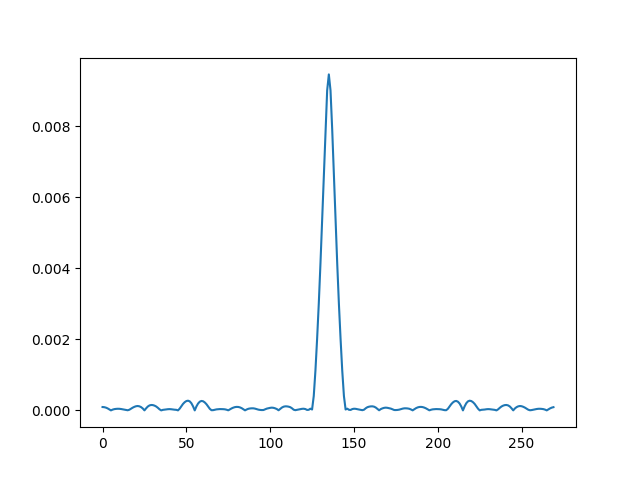

In [ ]:
OTF_temp = mathft(truth[0],904*10**-9)

plt.close(0)
plt.figure(0)
plt.plot(np.abs(OTF_temp)[:,270//2])

## Strehl



[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66. 67. 68. 69. 70. 71.
 72. 73. 74. 75. 76. 77. 78. 79.]


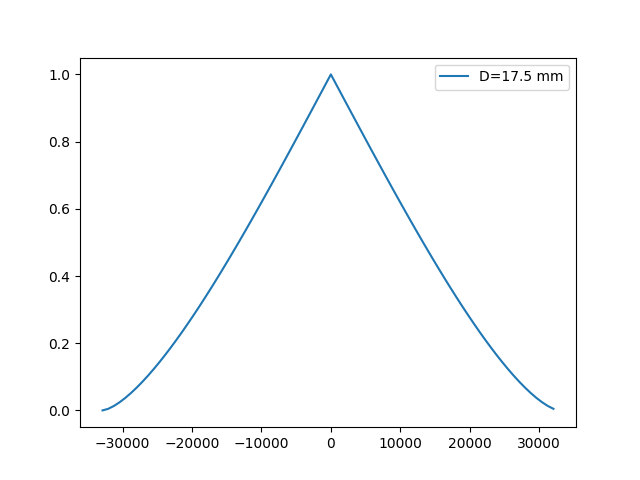

In [ ]:
dimmat_psf = 80 # px
wl = 532e-9 # [m]
D = 17.5e-3 # [m]
x = np.linspace(0,79,80)
print(x)

delta_nu = 2*D/(dimmat_psf*wl)  # Angular frequency sampling
nu_x = np.linspace(-dimmat_psf/2, dimmat_psf/2-1, dimmat_psf) * delta_nu
NU_X, NU_Y = np.meshgrid(nu_x, nu_x)
nu = np.sqrt(NU_X**2 + NU_Y**2)
nu_n = nu * wl / D
otf = myfunctions.telescope_otf(nu_n)

nu_x = np.linspace(-dimmat_psf/2, dimmat_psf/2-1, dimmat_psf)* delta_nu
plt.close(0)
plt.figure(0)
plt.plot(nu_x, otf[40,:], label = f"D={D*1e3} mm")
# plt.plot(nu_x*2*D[1]/(dimmat_psf*wl), otf[1,40,:], label = f"D={D[1]*1e3} mm")
plt.legend()


# relative_strehl_dist = (interpolation_strehl - truth_strehl) / truth_strehl

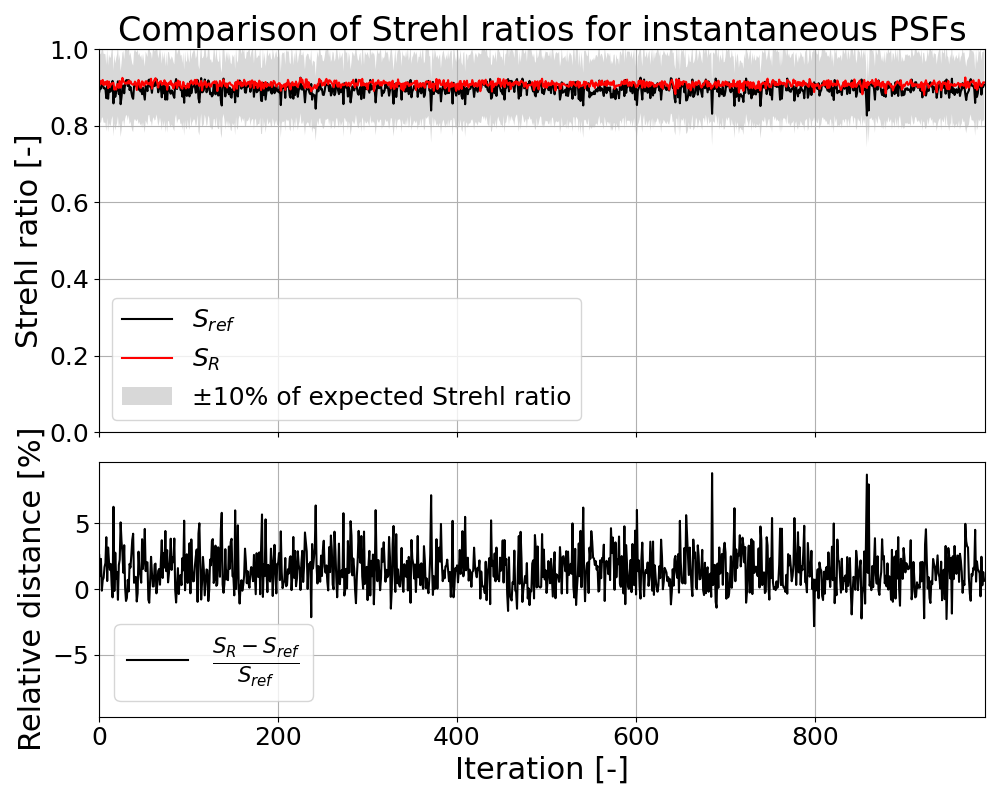

In [55]:
lower_bound = truth_strehl * 0.9  # -10%
upper_bound = truth_strehl * 1.1  # +10%

plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: Strehl ratios
ax.plot(truth_strehl, 'k', label=r'$S_{ref}$')
ax.plot(interpolation_strehl, 'r', label=r'$S_{R}$')
ax.set_ylim([0, 1])
ax.fill_between(range(len(truth_strehl)), lower_bound, upper_bound, 
                color='gray', alpha=0.3, edgecolor='none', label='±10% of expected Strehl ratio')
ax.set_ylabel('Strehl ratio [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of Strehl ratios for instantaneous PSFs", fontsize=BIGGER_SIZE)
ax.set_xlim([0, inference.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
ax2.plot(relative_strehl_dist * 100, 'k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$")
ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
symetric_lim = max(abs(np.min(relative_strehl_dist) * 110), abs(np.max(relative_strehl_dist) * 110))
ax2.set_ylim([-symetric_lim, symetric_lim])
ax2.legend(fontsize=MEDIUM_SIZE)
ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
ax2.set_xlim([0, inference.shape[0]])
ax2.grid()
ax2.tick_params(axis='x', labelsize=SMALL_SIZE)

plt.tight_layout()
plt.show()

In [ ]:
plt.close('all')
plt.figure(figsize=(10, 8))
plt.plot(truth_strehl,interpolation_strehl,'.k')
plt.xlim([0,1])
plt.ylim([0,1])
plt.xlabel('Truth Strehl', fontsize=MEDIUM_SIZE)
plt.ylabel('Interpolation Strehl', fontsize=MEDIUM_SIZE)
plt.xticks(fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.title(r'$S_R(S_{ref})$', fontsize=BIGGER_SIZE)
plt.grid(True)
plt.show()

NameError: name 'plt' is not defined

## Rotational average

1. Find center
2. Average the PSF
3. compare